# 04 — Selección de variables (reducción de dimensionalidad)
Entrada: 03_abt.parquet (23.191 clientes × 275 columnas)
Basado en la Clase 5: casi constantes → correlación → PCA → importancia por dimensión → bivariado → re-shape

In [1]:
import pandas as pd

import pandas as pd

ABT = pd.read_parquet('../data/processed/03_abt.parquet')
print(ABT.shape)
print(ABT.index.name)

(23191, 275)
None


In [2]:
X = ABT.drop(columns=["TGT", "client_id"])

In [3]:
prop_moda = X.apply(lambda col: col.value_counts(normalize=True).max())


In [4]:
prop_moda 

SavingAccount_Balance_Average    0.428399
CreditCard_Premium               0.884654
CreditCard_Active                0.647794
Loan_Active                      0.872019
Mortgage_Active                  0.977621
                                   ...   
Rev_0vs2_dir                     0.523134
Rev_0vs5_dir                     0.480316
Rev_2vs5_dir                     0.481049
Meses_con_tarjeta                0.647406
Meses_premium                    0.883964
Length: 273, dtype: float64

In [5]:
casi_const = prop_moda[prop_moda >= 0.99].sort_values(ascending=False)

In [6]:
casi_const

Series([], dtype: float64)

In [7]:
cols_casi_const = list(casi_const.index)

X = X.drop(columns=cols_casi_const)
print(X.shape)

(23191, 273)


In [8]:
print([c for c in X.columns if "obrand" in c.lower()])

[]


In [9]:
import numpy as np

corr = X.corr(numeric_only=True).abs()

mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pares = corr.where(mask).stack().dropna()

pares_altos = pares[pares > 0.95].sort_values(ascending=False)
print(len(pares_altos))
pares_altos.head(30)

227


SavingAccount_Service_Payment_Amount_sum     SavingAccount_Service_Payment_Amount_mean                1.0
CreditCard_Balance_ARG_sum_u3m               CreditCard_Balance_ARG_mean_u3m                          1.0
SavingAccount_Transactions_Transactions_sum  SavingAccount_Transactions_Transactions_mean             1.0
SavingAccount_ATM_Extraction_Amount_sum      SavingAccount_ATM_Extraction_Amount_mean                 1.0
CreditCard_Spending_1_Installment_sum_u3m    CreditCard_Spending_1_Installment_mean_u3m               1.0
CreditCard_Payment_Aut_Debit_sum_u3m         CreditCard_Payment_Aut_Debit_mean_u3m                    1.0
Operations_Bank_sum                          Operations_Bank_mean                                     1.0
Operations_Mobile_sum                        Operations_Mobile_mean                                   1.0
SavingAccount_CreditCard_Payment_Amount_sum  SavingAccount_CreditCard_Payment_Amount_mean             1.0
CreditCard_Revolving_sum                     C

In [10]:
y = ABT["TGT"]

# Cuánto se relaciona cada variable con el target
corr_target = X.corrwith(y).abs()

a_borrar = set()
for (v1, v2), r in pares_altos.items():
    if v1 in a_borrar or v2 in a_borrar:
        continue
    if corr_target[v1] >= corr_target[v2]:
        a_borrar.add(v2)
    else:
        a_borrar.add(v1)

print(len(a_borrar))
X_red = X.drop(columns=list(a_borrar))
print(X_red.shape)

106
(23191, 167)


In [11]:
pares_altos.head(15)

SavingAccount_Service_Payment_Amount_sum     SavingAccount_Service_Payment_Amount_mean       1.0
CreditCard_Balance_ARG_sum_u3m               CreditCard_Balance_ARG_mean_u3m                 1.0
SavingAccount_Transactions_Transactions_sum  SavingAccount_Transactions_Transactions_mean    1.0
SavingAccount_ATM_Extraction_Amount_sum      SavingAccount_ATM_Extraction_Amount_mean        1.0
CreditCard_Spending_1_Installment_sum_u3m    CreditCard_Spending_1_Installment_mean_u3m      1.0
CreditCard_Payment_Aut_Debit_sum_u3m         CreditCard_Payment_Aut_Debit_mean_u3m           1.0
Operations_Bank_sum                          Operations_Bank_mean                            1.0
Operations_Mobile_sum                        Operations_Mobile_mean                          1.0
SavingAccount_CreditCard_Payment_Amount_sum  SavingAccount_CreditCard_Payment_Amount_mean    1.0
CreditCard_Revolving_sum                     CreditCard_Revolving_mean                       1.0
Operations_ATM_sum            

In [12]:
pares_altos[pares_altos < 0.99].head(15)

SavingAccount_CreditCard_Payment_Amount_nunique  SavingAccount_CreditCard_Payment_Amount_meses_no_cero    0.988743
CreditCard_Total_Spending_mean                   CreditCard_Total_Spending_median                         0.987238
CreditCard_Total_Spending_sum                    CreditCard_Total_Spending_median                         0.987238
CreditCard_Total_Spending_meses_no_cero          CreditCard_Total_Spending_meses_no_cero_u3m              0.986963
CreditCard_Spending_Installments_sum             CreditCard_Spending_Installments_median                  0.986866
CreditCard_Spending_Installments_mean            CreditCard_Spending_Installments_median                  0.986866
SavingAccount_ATM_Extraction_Amount_nunique      SavingAccount_ATM_Extraction_Amount_meses_no_cero        0.986557
Investment_Numbers_mean                          Investment_Numbers_median                                0.986488
Investment_Numbers_sum                           Investment_Numbers_median      

In [13]:
### use algogrithms: lightgbm

In [14]:
%pip install lightgbm

Defaulting to user installation because normal site-packages is not writeable


Note: you may need to restart the kernel to use updated packages.


In [15]:
import pandas as pd
import lightgbm as lgb
from sklearn.model_selection import cross_val_score

# 1. Definir el modelo
modelo = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    random_state=42,
    verbose=-1
)

# 2. Chequear que sea un "good model"
auc = cross_val_score(modelo, X_red, y, cv=5, scoring="roc_auc")
print("AUC promedio:", round(auc.mean(), 3))

# 3. Entrenar y sacar las importancias
modelo.fit(X_red, y)
importancias = pd.Series(modelo.feature_importances_, index=X_red.columns)
importancias = importancias.sort_values(ascending=False)

top50 = importancias.head(50).index.tolist()
importancias.head(20)

AUC promedio: 0.841


Productos_por_Anio                       252
Meses_Antiguedad                         231
Meses_Ultimo_Producto                    214
Age_grp_ord                              183
Rev_0vs2_abs                             183
Tarj_pct_target                          178
CreditCard_Balance_ARG_max               175
CreditCard_Total_Limit_min               152
Rev_0vs5_abs                             148
SavingAccount_Balance_LastDate_min       145
Rev_2vs5_abs                             144
Meses_Primer_Ultimo                      143
CreditCard_Total_Spending_min_u3m        140
Saldo_Neto                               139
CreditCard_Revolving_min                 137
SavingAccount_Debits_Amounts             135
CreditCard_Spending_Installments_max     130
CreditCard_Total_Spending_min            130
CreditCard_Spending_1_Installment_max    127
SavingAccount_Balance_LastDate_median    127
dtype: int32

In [16]:
X_red['Meses_Ultimo_Producto'].min()

np.float64(0.0)

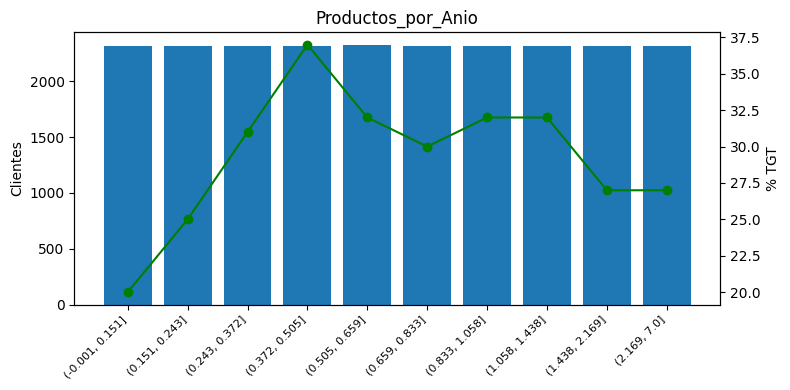

,Clientes,TGT,pct_TGT
grupo,,,
"(-0.001, 0.151]",2320,464,20.0
"(0.151, 0.243]",2320,589,25.0
"(0.243, 0.372]",2318,712,31.0
"(0.372, 0.505]",2320,861,37.0
"(0.505, 0.659]",2324,754,32.0
"(0.659, 0.833]",2319,705,30.0
"(0.833, 1.058]",2315,739,32.0
"(1.058, 1.438]",2317,735,32.0
"(1.438, 2.169]",2319,635,27.0


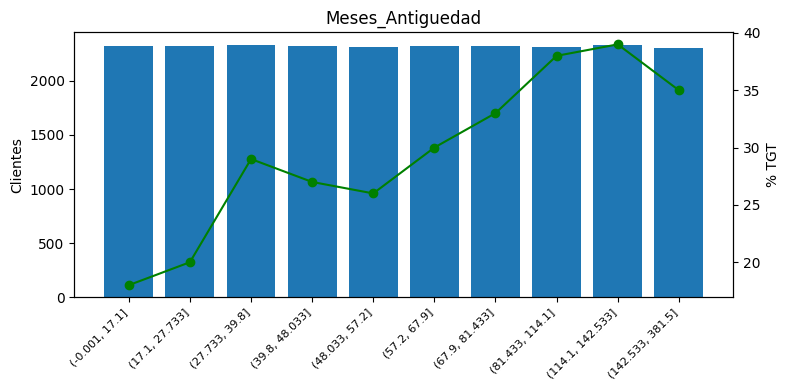

,Clientes,TGT,pct_TGT
grupo,,,
"(-0.001, 17.1]",2320,411,18.0
"(17.1, 27.733]",2322,453,20.0
"(27.733, 39.8]",2328,676,29.0
"(39.8, 48.033]",2319,617,27.0
"(48.033, 57.2]",2309,598,26.0
"(57.2, 67.9]",2322,698,30.0
"(67.9, 81.433]",2318,776,33.0
"(81.433, 114.1]",2317,888,38.0
"(114.1, 142.533]",2332,910,39.0


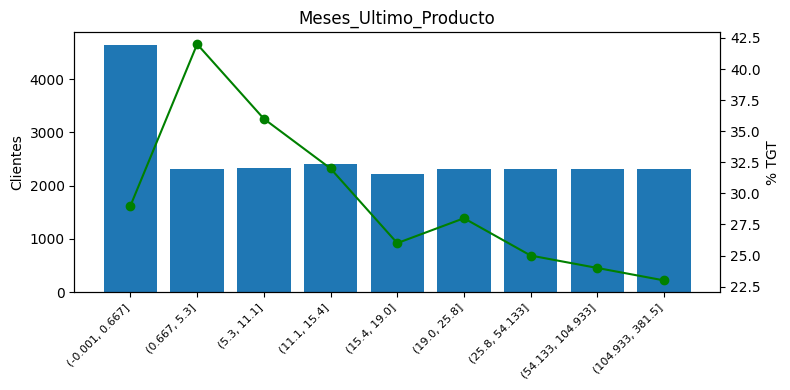

,Clientes,TGT,pct_TGT
grupo,,,
"(-0.001, 0.667]",4647,1326,29.0
"(0.667, 5.3]",2316,981,42.0
"(5.3, 11.1]",2334,840,36.0
"(11.1, 15.4]",2401,773,32.0
"(15.4, 19.0]",2221,579,26.0
"(19.0, 25.8]",2314,653,28.0
"(25.8, 54.133]",2321,575,25.0
"(54.133, 104.933]",2320,567,24.0
"(104.933, 381.5]",2317,529,23.0


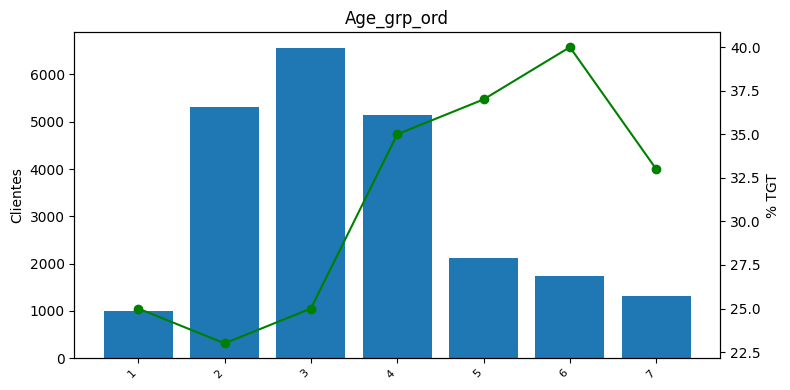

,Clientes,TGT,pct_TGT
grupo,,,
1,989,249,25.0
2,5308,1214,23.0
3,6563,1660,25.0
4,5149,1796,35.0
5,2122,776,37.0
6,1745,694,40.0
7,1315,434,33.0


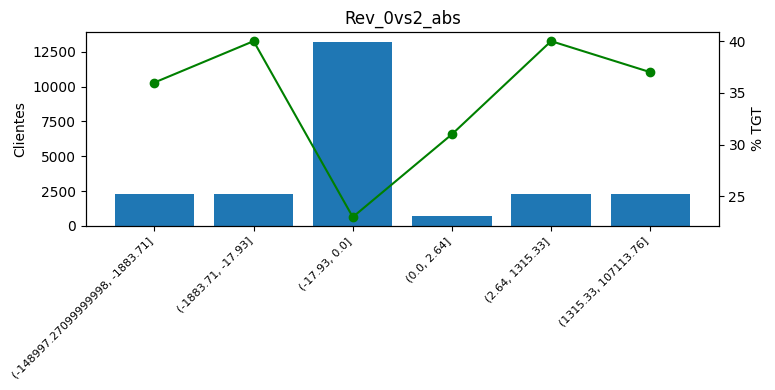

,Clientes,TGT,pct_TGT
grupo,,,
"(-148997.27099999998, -1883.71]",2320,834,36.0
"(-1883.71, -17.93]",2319,924,40.0
"(-17.93, 0.0]",13227,3070,23.0
"(0.0, 2.64]",687,216,31.0
"(2.64, 1315.33]",2319,922,40.0
"(1315.33, 107113.76]",2319,857,37.0


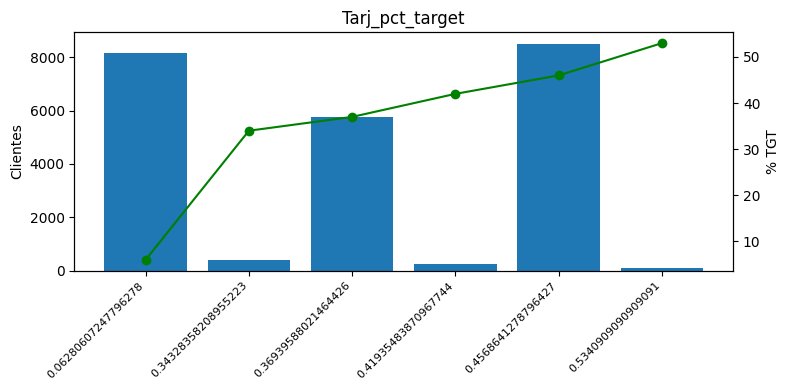

,Clientes,TGT,pct_TGT
grupo,,,
0.062806,8168,513,6.0
0.343284,402,138,34.0
0.369396,5777,2134,37.0
0.419355,248,104,42.0
0.456864,8508,3887,46.0
0.534091,88,47,53.0


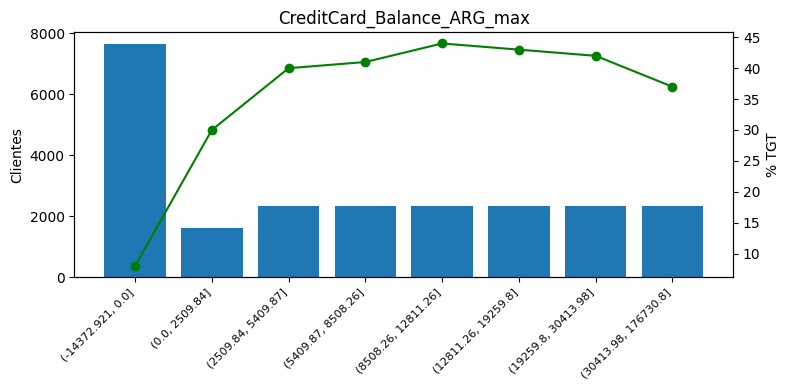

,Clientes,TGT,pct_TGT
grupo,,,
"(-14372.921, 0.0]",7651,629,8.0
"(0.0, 2509.84]",1626,480,30.0
"(2509.84, 5409.87]",2319,938,40.0
"(5409.87, 8508.26]",2319,942,41.0
"(8508.26, 12811.26]",2318,1026,44.0
"(12811.26, 19259.8]",2320,990,43.0
"(19259.8, 30413.98]",2319,964,42.0
"(30413.98, 176730.8]",2319,854,37.0


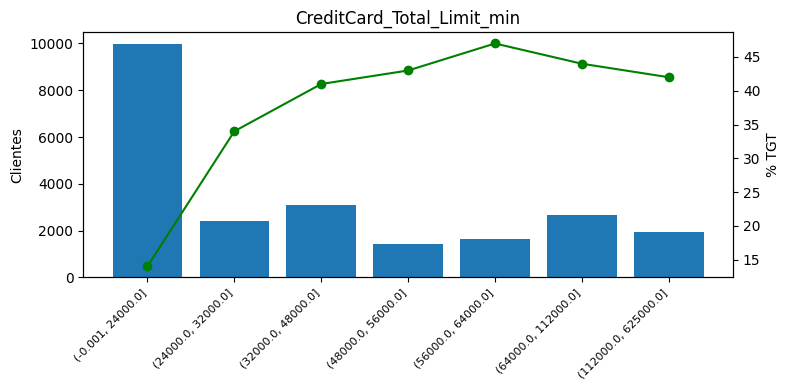

,Clientes,TGT,pct_TGT
grupo,,,
"(-0.001, 24000.0]",9977,1363,14.0
"(24000.0, 32000.0]",2430,821,34.0
"(32000.0, 48000.0]",3078,1258,41.0
"(48000.0, 56000.0]",1444,614,43.0
"(56000.0, 64000.0]",1646,768,47.0
"(64000.0, 112000.0]",2667,1184,44.0
"(112000.0, 625000.0]",1949,815,42.0


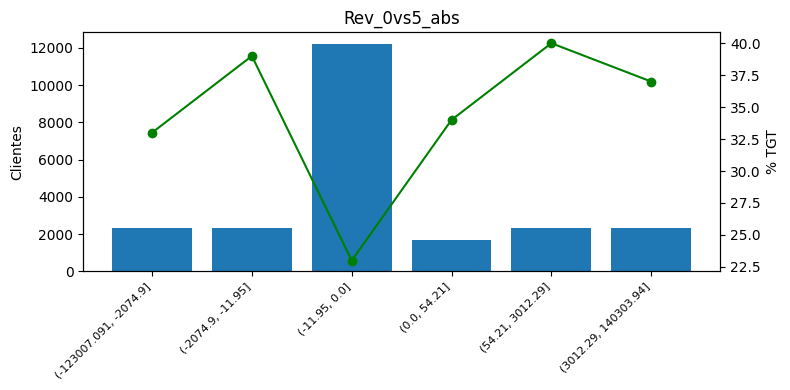

,Clientes,TGT,pct_TGT
grupo,,,
"(-123007.091, -2074.9]",2320,770,33.0
"(-2074.9, -11.95]",2319,899,39.0
"(-11.95, 0.0]",12219,2784,23.0
"(0.0, 54.21]",1695,568,34.0
"(54.21, 3012.29]",2319,938,40.0
"(3012.29, 140303.94]",2319,864,37.0


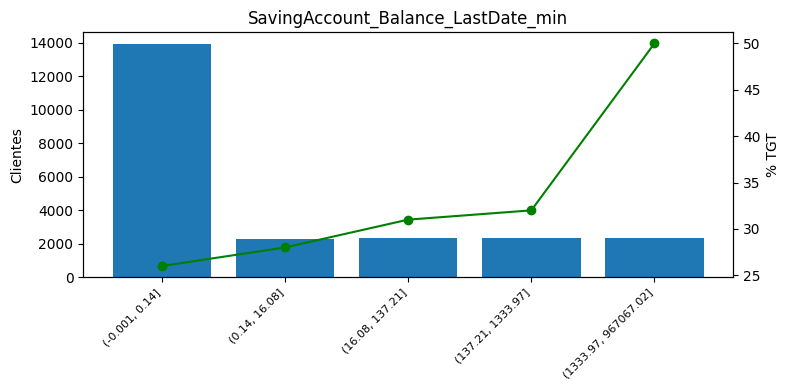

,Clientes,TGT,pct_TGT
grupo,,,
"(-0.001, 0.14]",13939,3570,26.0
"(0.14, 16.08]",2294,647,28.0
"(16.08, 137.21]",2320,710,31.0
"(137.21, 1333.97]",2319,741,32.0
"(1333.97, 967067.02]",2319,1155,50.0


In [17]:
import matplotlib.pyplot as plt

def bivariado(x, y, nombre, n_tramos=10):
    # 1. Armar los grupos
    if x.nunique() <= n_tramos:
        grupos = x                      # pocas categorías: cada valor es un grupo
    else:
        grupos = pd.qcut(x, q=n_tramos, duplicates="drop")   # muchos valores: tramos

    # 2. Tabla: Clientes, TGT y % TGT por grupo
    tabla = (
        pd.DataFrame({"grupo": grupos, "TGT": y})
        .groupby("grupo", observed=True)["TGT"]
        .agg(Clientes="count", TGT="sum", pct_TGT="mean")
    )
    tabla["pct_TGT"] = (tabla["pct_TGT"] * 100).round(0)

    # 3. Gráfico: barras = clientes, línea verde = % TGT
    fig, ax1 = plt.subplots(figsize=(8, 4))
    pos = range(len(tabla))
    ax1.bar(pos, tabla["Clientes"])
    ax1.set_ylabel("Clientes")

    
    ax1.set_xticks(pos)
    ax1.set_xticklabels([str(g) for g in tabla.index], rotation=45, ha="right", fontsize=8)
    ax2 = ax1.twinx()
    ax2.plot(pos, tabla["pct_TGT"], color="green", marker="o")
    ax2.set_ylabel("% TGT")
    plt.title(nombre)
    plt.tight_layout()
    plt.show()

    return tabla


# Correr para las top 10
for var in top50[:10]:
    display(bivariado(X_red[var], y, var))

In [18]:
X_red_original = X_red.copy()
top50_original = top50.copy()

In [19]:
X_red["CreditCard_Balance_ARG_max_0"] = (X_red["CreditCard_Balance_ARG_max"] > 0).astype(int)

In [20]:
X_red["CreditCard_Balance_ARG_max_0"].value_counts()

CreditCard_Balance_ARG_max_0
1    15540
0     7651
Name: count, dtype: int64

In [21]:
print([c for c in X_red.columns if "cambio" in c])

[]


In [22]:
X_red = X_red.drop(columns=["CreditCard_Balance_ARG_max"])
top50 = ["CreditCard_Balance_ARG_max_0" if c == "CreditCard_Balance_ARG_max" else c for c in top50]

In [23]:
X_top = X_red[top50]
print(X_top.shape)

(23191, 50)


In [24]:
auc_antes = cross_val_score(modelo, X_red_original[top50_original], y, cv=5, scoring="roc_auc").mean()
auc_despues = cross_val_score(modelo, X_top, y, cv=5, scoring="roc_auc").mean()

print("Antes:", round(auc_antes, 3))
print("Después:", round(auc_despues, 3))

Antes: 0.832
Después: 0.832


In [25]:
   X_top.assign(client_id=ABT["client_id"], TGT=y).to_parquet("../data/processed/04_abt_seleccion.parquet")